In [1]:
import pandas as pd

df = pd.read_csv('../data/raw/trips_raw.csv')
print(df.shape)

(1458644, 11)


In [2]:
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [3]:
df.tail()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
1458639,id2376096,2,2016-04-08 13:31:04,2016-04-08 13:44:02,4,-73.982201,40.745522,-73.994911,40.740170,N,778
1458640,id1049543,1,2016-01-10 07:35:15,2016-01-10 07:46:10,1,-74.000946,40.747379,-73.970184,40.796547,N,655
1458641,id2304944,2,2016-04-22 06:57:41,2016-04-22 07:10:25,1,-73.959129,40.768799,-74.004433,40.707371,N,764
1458642,id2714485,1,2016-01-05 15:56:26,2016-01-05 16:02:39,1,-73.982079,40.749062,-73.974632,40.757107,N,373
1458643,id1209952,1,2016-04-05 14:44:25,2016-04-05 14:47:43,1,-73.979538,40.781750,-73.972809,40.790585,N,198


In [9]:
df.index.values

array([      0,       1,       2, ..., 1458641, 1458642, 1458643],
      shape=(1458644,))

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 189.2 MB


In [ ]:
#thong ke mo ta
df.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


In [ ]:
#kiem tra gia tri khuyet
df.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [ ]:
#kiem tra trip duration = drop - pick
pickup = pd.to_datetime(df["pickup_datetime"])      #cho str ve gio
dropoff = pd.to_datetime(df["dropoff_datetime"])    #cho str ve gio

duration = (dropoff - pickup).dt.total_seconds()
print(duration)
mismatch = (duration - df["trip_duration"]).abs() > 1

print("Số dòng lệch > 1 giây:", mismatch.sum())

0           455.0
1           663.0
2          2124.0
3           429.0
4           435.0
            ...  
1458639     778.0
1458640     655.0
1458641     764.0
1458642     373.0
1458643     198.0
Length: 1458644, dtype: float64
Số dòng lệch > 1 giây: 0


In [ ]:
#bat thuong cua trip duration
print(df["trip_duration"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))
print()
print("Dưới 60s:", (df["trip_duration"] < 60).sum())
print("Trên 10800s:", (df["trip_duration"] > 10800).sum())          #3 tieng

#ta co max la 3,526,282 giay = 40 ngày, 19 giờ, 31 phút, 22 giây - gan 41 ngay
#phan vi 99%: 3.400 – 3.500 giay -> gan 1 tieng

count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
1%       8.700000e+01
5%       1.800000e+02
50%      6.620000e+02
95%      2.104000e+03
99%      3.440000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

Dưới 60s: 8595
Trên 10800s: 2112


In [ ]:
# Khám phá thời lượng theo giờ trên toàn bộ dữ liệu sau lọc
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

folders = [Path.cwd(), Path.cwd().parent, Path(r'C:\Users\Admin\Documents\TTNT\source\BTL\eta_predict')]
csv_path = next(p / 'data/processed/trips_clean.csv' for p in folders
                if (p / 'data/processed/trips_clean.csv').is_file())
clean = pd.read_csv(csv_path, usecols=['pickup_datetime', 'trip_duration'],
                    parse_dates=['pickup_datetime'])
clean['hour'] = clean['pickup_datetime'].dt.hour
clean['is_weekend'] = clean['pickup_datetime'].dt.dayofweek >= 5

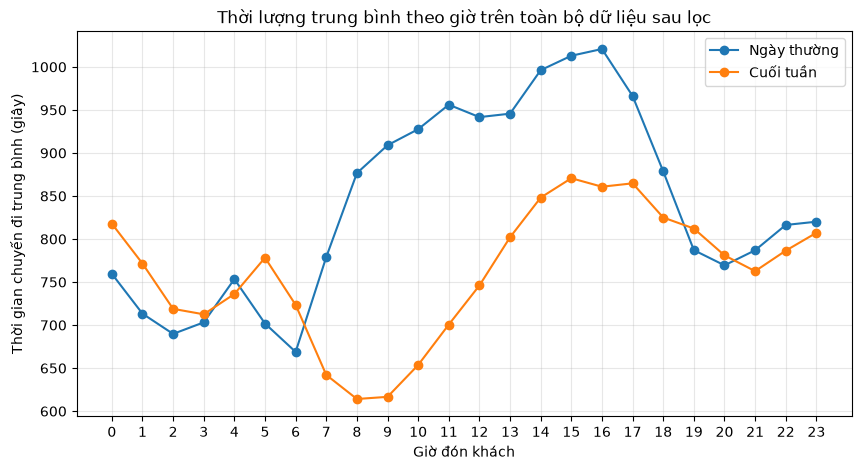

In [ ]:
#bieu do thoi gian trung binh theo 24 gio
avg = clean.groupby(["hour", "is_weekend"])["trip_duration"].mean().unstack()

avg.plot(marker="o", figsize=(10, 5))
plt.xticks(range(24))
plt.xlabel("Giờ đón khách")
plt.ylabel("Thời gian chuyến đi trung bình (giây)")
plt.title("Thời lượng trung bình theo giờ trên toàn bộ dữ liệu sau lọc")
plt.legend(["Ngày thường", "Cuối tuần"])
plt.grid(alpha=0.3)

plt.show()